<a href="https://colab.research.google.com/github/amoghkamath06/Bio_Inspired_system/blob/main/ant_colony.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best route: [8 2 7 6 4 5 3 1 8]
Best route distance: 26.6794



,Iteration,BestDistance,AverageDistance
0,1,27.835960,33.688087
1,2,27.835960,31.702430
2,3,27.106813,29.196476
3,4,26.679408,31.280847
4,5,26.679408,30.544749
5,6,26.679408,30.245494
6,7,26.679408,28.782501
7,8,26.679408,29.946080
8,9,26.679408,28.822578
9,10,26.679408,29.139811


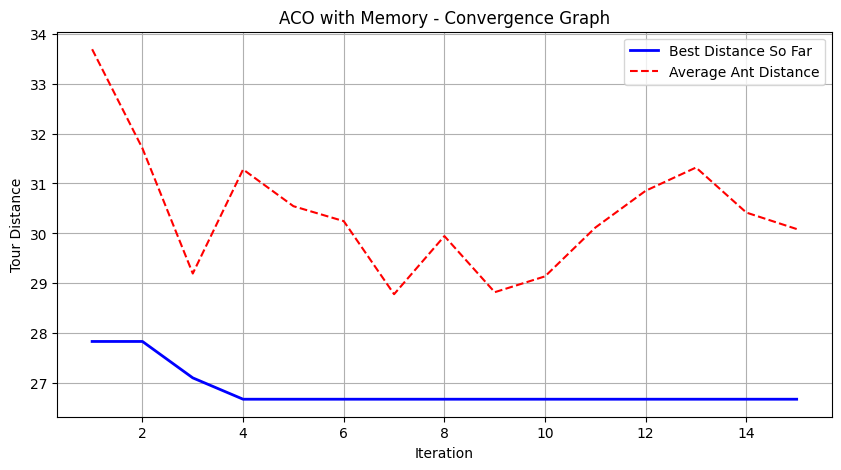

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible results
np.random.seed(1)

# Coordinates of 8 cities: [x, y]
cities = np.array([
    [1, 2],
    [3, 5],
    [5, 2],
    [7, 6],
    [8, 1],
    [6, 8],
    [2, 8],
    [4, 4]
])

n = cities.shape[0]

# Calculate distance between every pair of cities
D = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        D[i, j] = np.linalg.norm(cities[i] - cities[j])

# ACO parameters
nAnts = n
maxIter = 15
alpha = 1.0       # Pheromone importance
beta = 3.0        # Distance importance
rho = 0.5        # Pheromone evaporation
Q = 100.0        # Pheromone deposit constant
memoryWeight = 2.0 # Extra influence of best-known route

# Initialize pheromone and visibility
tau = np.ones((n, n))
eta = 1.0 / (D + np.finfo(float).eps)
np.fill_diagonal(tau, 0)
np.fill_diagonal(eta, 0)

bestLength = float('inf')
bestTour = []
bestHistory = np.zeros(maxIter)
meanHistory = np.zeros(maxIter)

# Main ACO loop
for iter_idx in range(maxIter):
    tours = np.zeros((nAnts, n), dtype=int)
    lengths = np.zeros(nAnts)

    # Each ant builds a complete tour
    for k in range(nAnts):
        tour = np.zeros(n, dtype=int)
        visited = np.zeros(n, dtype=bool)

        current = np.random.randint(0, n)
        tour[0] = current
        visited[current] = True

        for step in range(1, n):
            # Calculate probability of choosing each city
            p = (tau[current, :] ** alpha) * (eta[current, :] ** beta)
            p[visited] = 0

            p_sum = np.sum(p)
            if p_sum == 0:
                candidates = np.where(~visited)[0]
                next_city = np.random.choice(candidates)
            else:
                p = p / p_sum
                # Roulette wheel selection
                next_city = np.random.choice(np.arange(n), p=p)

            tour[step] = next_city
            visited[next_city] = True
            current = next_city

        # Include the return trip to the starting city
        tour_with_return = np.append(tour, tour[0])
        tour_length = sum(D[tour_with_return[i], tour_with_return[i+1]] for i in range(n))
        lengths[k] = tour_length
        tours[k, :] = tour

    # Update the best solution found so far
    min_len_idx = np.argmin(lengths)
    iterationBest = lengths[min_len_idx]

    if iterationBest < bestLength:
        bestLength = iterationBest
        bestTour = tours[min_len_idx, :].copy()

    # Record graph data
    bestHistory[iter_idx] = bestLength
    meanHistory[iter_idx] = np.mean(lengths)

    # Evaporate pheromones
    tau = (1.0 - rho) * tau

    # Deposit pheromone from all ants
    for k in range(nAnts):
        tour = tours[k, :]
        for j in range(n):
            a = tour[j]
            b = tour[(j + 1) % n]
            tau[a, b] += Q / lengths[k]
            tau[b, a] += Q / lengths[k]

    # Memory: reinforce the best-known route
    for j in range(n):
        a = bestTour[j]
        b = bestTour[(j + 1) % n]
        tau[a, b] += memoryWeight * Q / bestLength
        tau[b, a] += memoryWeight * Q / bestLength

# Display final result
print("Best route:", np.append(bestTour + 1, bestTour[0] + 1))  # Offset for 1-based indexing output
print(f"Best route distance: {bestLength:.4f}\n")

# Create numerical output for graphing
results = pd.DataFrame({
    'Iteration': np.arange(1, maxIter + 1),
    'BestDistance': bestHistory,
    'AverageDistance': meanHistory
})
display(results)

# Save graph data
results.to_csv('ACO_Graph_Data.csv', index=False)

# GRAPH: Convergence
plt.figure(figsize=(10, 5))
plt.plot(results['Iteration'], results['BestDistance'], 'b-', label='Best Distance So Far', linewidth=2)
plt.plot(results['Iteration'], results['AverageDistance'], 'r--', label='Average Ant Distance', linewidth=1.5)
plt.xlabel('Iteration')
plt.ylabel('Tour Distance')
plt.title('ACO with Memory - Convergence Graph')
plt.legend()
plt.grid(True)
plt.show()